# Лабораторна робота № 3
## Діагностика шкал вимірювання

Курс СК26 «Інтелектуальний аналіз та візуалізація даних»

**Тривалість:** 2 год аудиторно + 3 год самостійно · **Оцінка:** 4 бали
**Файли:** `Ковід_дані_навчальні.xlsx`, `ЛР3_помилковий_аналіз.ipynb`

---

Шкала вимірювання визначає, які операції над змінною взагалі мають сенс.
Комп'ютер цього не знає: він порахує середнє від номера телефону й не поскаржиться.
Знати має вимірювач.

У цій роботі ви складаєте **паспорт восьми змінних** свого варіанта, показуєте на
власних даних, які статистики для них недопустимі, і виправляєте чужий аналіз,
де таких помилок десять.

In [73]:
ПРІЗВИЩЕ_ІМЯ = 'Мартин Максим'
ГРУПА        = 'ШІ-31'
НОМЕР        = 14

assert ПРІЗВИЩЕ_ІМЯ and ГРУПА and НОМЕР, 'Заповніть три поля вище'
assert 1 <= НОМЕР <= 30, 'Номер має бути від 1 до 30'

In [74]:
import os
ФАЙЛИ_ДАНИХ = ['lr3_variants_student.json', 'Ковід_дані_навчальні.xlsx']
бракує = [f for f in ФАЙЛИ_ДАНИХ if not os.path.exists(f)]
if бракує:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f'Покладіть поруч із ноутбуком: {бракує}')
    print('Завантажте файли:', ', '.join(бракує))
    files.upload()
print('Файли даних на місці:', all(os.path.exists(f) for f in ФАЙЛИ_ДАНИХ))

Файли даних на місці: True


In [75]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_colwidth', 60)

ВАРІАНТИ = json.load(open('lr3_variants_student.json'))
В = ВАРІАНТИ[НОМЕР - 1]

print('=' * 74)
print(f'ВАРІАНТ {В["варіант"]}   ·   {ПРІЗВИЩЕ_ІМЯ}   ·   {ГРУПА}')
print('=' * 74)
print()
print('Ваші вісім стовпців:')
for i, c in enumerate(В['стовпці'], 1):
    print(f'   {i}. {c}')
print()
print('Ваша пара для аналізу зв’язку:', ' та '.join(В['пара']))
print()
print('Ваше додаткове питання:')
print('  ', В['питання'])

ВАРІАНТ 14   ·   Мартин Максим   ·   ШІ-31

Ваші вісім стовпців:
   1. номер і/х
   2. КТ опис
   3. ЛН
   4. Виписка
   5. КТ
   6. Прокальцитонін
   7. БРзаг2
   8. Сечов1

Ваша пара для аналізу зв’язку: ступінь КТ та ЛН

Ваше додаткове питання:
   У чому різниця між шкалою інтервалів і шкалою відношень? Знайдіть у файлі по одному прикладу кожної та поясніть, яка операція допустима для другої, але не для першої.


In [76]:
ФАЙЛ = 'Ковід_дані_навчальні.xlsx'
df = pd.read_excel(ФАЙЛ, sheet_name='Лист1', engine='openpyxl')
МОЇ = В['стовпці']

print('Розмір набору:', df.shape)
df[МОЇ].head(8)

Розмір набору: (121, 77)


,номер і/х,КТ опис,ЛН,Виписка,КТ,Прокальцитонін,БРзаг2,Сечов1
0,2377/239,CO-Rads5,ІІІ-IV,2022-03-10 00:00:00,20-30%,0.126,17.0,5.1
1,1121/19,CO-Rads6,ІІ-ІІІ,2022-03-16 00:00:00,30-35%,NaN,13.6,6.6
2,283/674,"КТ-4, CO-Rads6",ІІ,2022-01-18 00:00:00,70-80%,NaN,18.7,7.0
3,2372/513,NaN,ІІІ-IV,2022-01-13 00:00:00,0.8,NaN,13.6,9.5
4,1441/671,NaN,ІІ-ІІІ,2022-03-11 00:00:00,NaN,NaN,15.3,5.2
5,2573/354,"КТ-2, СО-Rads6",ІІ-ІІІ,2021-12-26 00:00:00,30-40%,NaN,15.3,14.0
6,1762/555,"КТ-3, СО-Rads5",ІІ-ІІІ,2022-05-11 00:00:00,60-65%,NaN,15.3,5.7
7,2664/348,"КТ-1, СО-Rads5",І,2022-05-28 00:00:00,до 17%,NaN,15.3,9.1


---
# Етап 1. Паспорт змінних

Для кожного з восьми стовпців визначте шкалу вимірювання. Спирайтеся не на тип даних
у pandas, а на **зміст величини**: що означають її значення і які порівняння між ними
мають сенс.

Нагадування:

| Шкала | Ознака |
|---|---|
| Номінальна | значення можна лише порівняти на рівність |
| Порядкова | є природний порядок, але відстані між сусідніми рівнями невідомі |
| Інтервальна | різниці мають сенс, нуль умовний |
| Відношень | є природний нуль, відношення мають сенс |
| Абсолютна | природні і нуль, і одиниця вимірювання |

Окремо позначайте **ідентифікатори** — значення, що не є величиною взагалі
(номер історії хвороби, прізвище, телефон).

In [77]:
df[МОЇ].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   номер і/х       121 non-null    object 
 1   КТ опис         10 non-null     object 
 2   ЛН              121 non-null    object 
 3   Виписка         120 non-null    object 
 4   КТ              44 non-null     object 
 5   Прокальцитонін  46 non-null     float64
 6   БРзаг2          101 non-null    float64
 7   Сечов1          117 non-null    float64
dtypes: float64(3), object(5)
memory usage: 7.7+ KB


In [78]:
for c in МОЇ:
    з = df[c].dropna()
    типи = ', '.join(f'{t.__name__}×{n}' for t, n in з.map(type).value_counts().items())
    print(f'--- {c}')
    print(f'    непорожніх {len(з)} з {len(df)} | унікальних {з.nunique()} | типи: {типи}')
    print(f'    приклади: {[repr(v) for v in з.unique()[:4]]}')
    print()

--- номер і/х
    непорожніх 121 з 121 | унікальних 119 | типи: int×65, str×56
    приклади: ["'2377/239'", "'1121/19'", "'283/674'", "'2372/513'"]

--- КТ опис
    непорожніх 10 з 121 | унікальних 10 | типи: str×10
    приклади: ["'CO-Rads5'", "'CO-Rads6'", "'КТ-4, CO-Rads6'", "'КТ-2, СО-Rads6'"]

--- ЛН
    непорожніх 121 з 121 | унікальних 6 | типи: str×121
    приклади: ["'ІІІ-IV'", "'ІІ-ІІІ'", "'ІІ'", "'І'"]

--- Виписка
    непорожніх 120 з 121 | унікальних 90 | типи: datetime×118, str×2
    приклади: ['datetime.datetime(2022, 3, 10, 0, 0)', 'datetime.datetime(2022, 3, 16, 0, 0)', 'datetime.datetime(2022, 1, 18, 0, 0)', 'datetime.datetime(2022, 1, 13, 0, 0)']

--- КТ
    непорожніх 44 з 121 | унікальних 26 | типи: float×27, str×17
    приклади: ["'20-30%'", "'30-35%'", "'70-80%'", '0.8']

--- Прокальцитонін
    непорожніх 46 з 121 | унікальних 17 | типи: float×46
    приклади: ['np.float64(0.126)', 'np.float64(0.9)', 'np.float64(0.1)', 'np.float64(0.104)']

--- БРзаг2
    непорож

### Заповніть паспорт

Для кожного стовпця вкажіть шкалу та **обґрунтування** — одне речення про те,
чому саме ця шкала. Обґрунтування оцінюється, назва шкали сама по собі — ні.

In [79]:
ПАСПОРТ = {
    'номер і/х': ('ідентифікатор',
        'Номер історії хвороби лише позначає запис: 1837 не «більший» за 393, середнє номерів не є величиною, '
        'і навіть як ключ номер ненадійний — 1837 і 2526 трапляються у двох різних пацієнтів.'),
    'КТ опис': ('номінальна',
        'Вільний текстовий опис КТ: два записи можна лише порівняти на збіг, порядку між «CO-Rads5» і '
        '«дв полісегм інтерст пнев» немає; заповнено 10 рядків зі 121, і всі 10 різні.'),
    'ЛН': ('порядкова',
        'Ступінь легеневої недостатності I < I-II < II < II-III < III < III-IV має природний порядок, '
        'але відстані між ступенями невідомі: не можна сказати, що III «утричі гірше» за I.'),
    'Виписка': ('інтервальна',
        'Дата виписки (у померлих — дата смерті): різниця дат має зміст, бо Виписка − Поступлення дає '
        'тривалість лікування в днях, а нуль умовний — pandas рахує дні від 1970-01-01, Excel від 1899-12-30.'),
    'КТ': ('абсолютна',
        'Частка ураженого об’єму легень: природні і нуль (уражень немає), і одиниця (уся легеня = 1, тобто 100%), '
        'тож 0.6 справді вдвічі більше за 0.3; 16 записів зроблено текстом на кшталт «70-80%».'),
    'Прокальцитонін': ('відношень',
        'Концентрація прокальцитоніну в крові, нг/мл: нуль природний (речовини немає), відношення мають зміст '
        '(2 нг/мл удвічі більше за 1), але одиниця вимірювання умовна, тому шкала не абсолютна.'),
    'БРзаг2': ('відношень',
        'Загальний білірубін при повторному аналізі, мкмоль/л: нуль природний, відношення мають зміст, а одиниця '
        'умовна — 90 зі 101 значення кратні 1.7, тобто їх перераховано з мг/дл (0.1 мг/дл ≈ 1.7 мкмоль/л).'),
    'Сечов1': ('відношень',
        'Сечовина крові при першому аналізі, ммоль/л: природний нуль і зміст відношень (6.0 удвічі більше за 3.0), '
        'одиниця умовна; значення 60 і 68 при нормальному креатиніні, ймовірно, записані в мг/дл.'),
}

for c in МОЇ:
    ПАСПОРТ.setdefault(c, ('', ''))

pd.set_option('display.max_colwidth', None)
паспорт_df = pd.DataFrame(
    [(c, ПАСПОРТ[c][0], ПАСПОРТ[c][1]) for c in МОЇ],
    columns=['Стовпець', 'Шкала', 'Обґрунтування'])
паспорт_df

,Стовпець,Шкала,Обґрунтування
0,номер і/х,ідентифікатор,"Номер історії хвороби лише позначає запис: 1837 не «більший» за 393, середнє номерів не є величиною, і навіть як ключ номер ненадійний — 1837 і 2526 трапляються у двох різних пацієнтів."
1,КТ опис,номінальна,"Вільний текстовий опис КТ: два записи можна лише порівняти на збіг, порядку між «CO-Rads5» і «дв полісегм інтерст пнев» немає; заповнено 10 рядків зі 121, і всі 10 різні."
2,ЛН,порядкова,"Ступінь легеневої недостатності I < I-II < II < II-III < III < III-IV має природний порядок, але відстані між ступенями невідомі: не можна сказати, що III «утричі гірше» за I."
3,Виписка,інтервальна,"Дата виписки (у померлих — дата смерті): різниця дат має зміст, бо Виписка − Поступлення дає тривалість лікування в днях, а нуль умовний — pandas рахує дні від 1970-01-01, Excel від 1899-12-30."
4,КТ,абсолютна,"Частка ураженого об’єму легень: природні і нуль (уражень немає), і одиниця (уся легеня = 1, тобто 100%), тож 0.6 справді вдвічі більше за 0.3; 16 записів зроблено текстом на кшталт «70-80%»."
5,Прокальцитонін,відношень,"Концентрація прокальцитоніну в крові, нг/мл: нуль природний (речовини немає), відношення мають зміст (2 нг/мл удвічі більше за 1), але одиниця вимірювання умовна, тому шкала не абсолютна."
6,БРзаг2,відношень,"Загальний білірубін при повторному аналізі, мкмоль/л: нуль природний, відношення мають зміст, а одиниця умовна — 90 зі 101 значення кратні 1.7, тобто їх перераховано з мг/дл (0.1 мг/дл ≈ 1.7 мкмоль/л)."
7,Сечов1,відношень,"Сечовина крові при першому аналізі, ммоль/л: природний нуль і зміст відношень (6.0 удвічі більше за 3.0), одиниця умовна; значення 60 і 68 при нормальному креатиніні, ймовірно, записані в мг/дл."


In [80]:
ДОПУСТИМІ = {'номінальна', 'порядкова', 'інтервальна', 'відношень',
             'абсолютна', 'ідентифікатор'}
for c in МОЇ:
    ш, об = ПАСПОРТ[c]
    assert ш.strip().lower() in ДОПУСТИМІ, f'{c}: шкалу «{ш}» не розпізнано'
    assert len(об.strip()) >= 25, f'{c}: обґрунтування закоротке'
print('Самоперевірка 1 пройдена: усі вісім стовпців мають шкалу та обґрунтування.')

Самоперевірка 1 пройдена: усі вісім стовпців мають шкалу та обґрунтування.


---
# Етап 2. Допустимі статистики

Для кожного стовпця обчисліть **тільки те, що дозволяє його шкала**.

* номінальна та ідентифікатор — мода, частоти
* порядкова — додатково медіана та квантилі
* інтервальна — додатково середнє та стандартне відхилення
* відношень і абсолютна — усе, зокрема коефіцієнт варіації

Якщо для стовпця не можна порахувати нічого, крім частот, — так і напишіть.

In [81]:
import re
from scipy import stats

ПОРЯДОК = {
    'ЛН':         ['I', 'I-II', 'II', 'II-III', 'III', 'III-IV'],
    'ступінь КТ': ['легкий', 'середній', 'важкий', 'вкрай важкий', 'критичний'],
}

СТУПІНЬ_КТ = {'легкий': 'легкий', 'легка': 'легкий',
              'середній': 'середній', 'сердній': 'середній', 'серед ступ': 'середній', 'серед ступеня': 'середній',
              'важкий': 'важкий', 'вкрай важкий': 'вкрай важкий', 'критичний': 'критичний'}


def впорядкувати(стовпець):
    """Порядкова змінна як впорядкована категорія pandas."""
    s = df[стовпець].str.strip()
    if стовпець == 'ЛН':
        s = s.str.replace('\u0406', 'I')
    else:
        s = s.map(СТУПІНЬ_КТ)
    return pd.Series(pd.Categorical(s, categories=ПОРЯДОК[стовпець], ordered=True),
                     index=df.index, name=стовпець)


def кт_частка(v):
    """КТ записано двома способами: часткою (0.3) і текстом у відсотках («25-30%», «до 17%»)."""
    if isinstance(v, (int, float, np.number)):
        return float(v)
    числа = [float(ч.replace(',', '.')) for ч in re.findall(r'\d+(?:[.,]\d+)?', str(v))]
    return np.mean(числа) / 100 if числа else np.nan


def значення(стовпець):
    """Значення стовпця в його шкалі."""
    if стовпець in ПОРЯДОК:
        return впорядкувати(стовпець)
    if стовпець == 'КТ':
        return df['КТ'].map(кт_частка)
    if стовпець == 'Виписка':
        return pd.to_datetime(df['Виписка'], errors='coerce')
    return df[стовпець]


def рядком(s):
    """Частоти рівнів одним рядком: «I 12, I-II 9, …»."""
    return ', '.join(f'{рівень} {n}' for рівень, n in s.value_counts(sort=False).items())


випис = значення('Виписка')
кт = значення('КТ')
print('ЛН:         ', рядком(значення('ЛН')))
print('ступінь КТ: ', df['ступінь КТ'].nunique(), 'написань звели до 5 рівнів:')
print('            ', рядком(значення('ступінь КТ')))
print(f"КТ:          чисел було {pd.to_numeric(df['КТ'], errors='coerce').notna().sum()}, "
      f"стало {кт.notna().sum()} з {df['КТ'].notna().sum()} непорожніх записів")
print('Виписка:     не є датами —', df.loc[випис.isna() & df['Виписка'].notna(), 'Виписка'].tolist())
print()

print("sorted(['ІІ', 'ІІІ', 'IV']) =", sorted(['ІІ', 'ІІІ', 'IV']), '← «IV» опинилося першим')

ЛН:          I 12, I-II 9, II 21, II-III 59, III 17, III-IV 3
ступінь КТ:  12 написань звели до 5 рівнів:
             легкий 7, середній 18, важкий 10, вкрай важкий 4, критичний 3
КТ:          чисел було 27, стало 43 з 44 непорожніх записів
Виписка:     не є датами — ['24.024.2021', '20.24.2021']

sorted(['ІІ', 'ІІІ', 'IV']) = ['IV', 'ІІ', 'ІІІ'] ← «IV» опинилося першим


In [82]:
def показати(v):
    """Вигляд для друку: дати без часу, тривалості в днях, три знаки після коми."""
    if isinstance(v, pd.Timestamp):
        return str(v.date())
    if isinstance(v, pd.Timedelta):
        return f'{v / pd.Timedelta(days=1):.1f} дн.'
    if isinstance(v, (float, np.floating)):
        return round(float(v), 3)
    if isinstance(v, dict):
        return {показати(k): int(n) for k, n in v.items()}
    return v


def допустима_статистика(стовпець, шкала):
    """Повертає словник статистик, дозволених для цієї шкали."""
    з = значення(стовпець).dropna()
    р = {'непорожніх': len(з), 'унікальних': з.nunique()}
    ш = шкала.strip().lower()

    if ш in ('ідентифікатор',):
        р['повторів'] = int(з.duplicated().sum())
        return р

    частоти = з.value_counts()
    моди = частоти[частоти == частоти.max()].index
    if частоти.max() == 1:
        р['мода'] = 'немає: усі значення різні'
    elif len(моди) > 1:
        р['мода'] = f'не єдина: {len(моди)} значень по {частоти.max()} рази'
    else:
        р['мода'] = показати(моди[0])
    р['частоти, топ-3'] = показати(частоти.head(3).to_dict())
    if ш == 'номінальна':
        return р

    if ш == 'порядкова':
        коди = з.cat.codes.astype(int)
        Q1, Me, Q3 = (int(q) for q in коди.quantile([0.25, 0.5, 0.75], interpolation='lower'))
        р['медіана'] = з.cat.categories[Me]
        р['квартилі Q1 … Q3'] = f'{з.cat.categories[Q1]} … {з.cat.categories[Q3]}'
        return р

    р['медіана'] = показати(з.median())
    р['квартилі Q1 … Q3'] = f'{показати(з.quantile(0.25))} … {показати(з.quantile(0.75))}'
    р['середнє'] = показати(з.mean())
    р['ст. відхилення'] = показати(з.std())
    р['розмах (max − min)'] = показати(з.max() - з.min())
    if ш == 'інтервальна':
        return р

    р['коеф. варіації, %'] = показати(100 * з.std() / з.mean())
    р['геом. середнє'] = показати(stats.gmean(з)) if (з > 0).all() else 'не визначене: є нулі'
    return р


for c in МОЇ:
    print(f'--- {c}  ({ПАСПОРТ[c][0]})')
    for назва, v in допустима_статистика(c, ПАСПОРТ[c][0]).items():
        print(f'    {назва:<20} {v}')
    print()

--- номер і/х  (ідентифікатор)
    непорожніх           121
    унікальних           119
    повторів             2

--- КТ опис  (номінальна)
    непорожніх           10
    унікальних           10
    мода                 немає: усі значення різні
    частоти, топ-3       {'CO-Rads5': 1, 'CO-Rads6': 1, 'КТ-4, CO-Rads6': 1}

--- ЛН  (порядкова)
    непорожніх           121
    унікальних           6
    мода                 II-III
    частоти, топ-3       {'II-III': 59, 'II': 21, 'III': 17}
    медіана              II-III
    квартилі Q1 … Q3     II … II-III

--- Виписка  (інтервальна)
    непорожніх           118
    унікальних           88
    мода                 не єдина: 6 значень по 3 рази
    частоти, топ-3       {'2021-09-07': 3, '2021-09-15': 3, '2021-09-11': 3}
    медіана              2022-03-15
    квартилі Q1 … Q3     2021-11-16 … 2022-04-27
    середнє              2022-01-29
    ст. відхилення       109.5 дн.
    розмах (max − min)   421.0 дн.

--- КТ  (абсолютна)
    н

---
# Етап 3. Три безглузді числа

`df.describe()` порахує статистики для всього, що схоже на число. Частина цих чисел
не має жодного змісту.

Знайдіть **щонайменше три** такі числа у своєму наборі: обчисліть їх, а потім
поясніть, чому кожне з них безглузде.

In [83]:
df[МОЇ].describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
номер і/х,121.0,119.0,2526.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
КТ опис,10,10,CO-Rads5,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ЛН,121,6,ІІ-ІІІ,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Виписка,120,90,2021-11-19 00:00:00,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
КТ,44.0,26.0,0.3,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Прокальцитонін,46.0,NaN,NaN,NaN,0.752957,3.010375,0.043,0.1,0.1,0.1205,18.22
БРзаг2,101.0,NaN,NaN,NaN,16.216832,5.537094,7.4,13.6,15.3,18.7,60.5
Сечов1,117.0,NaN,NaN,NaN,8.93188,8.174368,3.1,5.5,7.2,9.5,68.0


In [84]:
наївно = df[МОЇ].apply(pd.to_numeric, errors='coerce')
наївно.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
номер і/х,65.0,1770.123,979.051,42.000,893.00,1805.0,2455.00,3379.00
КТ опис,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ЛН,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Виписка,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
КТ,27.0,0.396,0.229,0.050,0.25,0.3,0.55,0.80
Прокальцитонін,46.0,0.753,3.010,0.043,0.10,0.1,0.12,18.22
БРзаг2,101.0,16.217,5.537,7.400,13.60,15.3,18.70,60.50
Сечов1,117.0,8.932,8.174,3.100,5.50,7.2,9.50,68.00


In [85]:
номер = наївно['номер і/х']
лн_алф = df['ЛН'].astype('category').cat.codes
лн_пів = np.array([1, 1.5, 2, 2.5, 3, 3.5])[лн_алф]
дні_1970 = (випис - pd.Timestamp('1970-01-01')).dt.days
дні_2021 = (випис - pd.Timestamp('2021-01-01')).dt.days
кт_наївно = наївно['КТ']
текст_кт = df['КТ'].map(lambda v: isinstance(v, str))
пкт = df['Прокальцитонін'].dropna()

БЕЗГЛУЗДІ = [
    ('номер і/х', 'середнє', round(номер.mean(), 1),
     f'Номер історії хвороби — ідентифікатор: «середній номер» не належить жодному пацієнтові й нічого не '
     f'вимірює. До того ж pandas узяв лише {номер.notna().sum()} номерів зі {len(df)}, а «2377/239» мовчки зробив NaN.'),
    ('ЛН', 'середнє кодів', round(лн_алф.mean(), 2),
     f'Порядкова шкала: коди 0–5 pandas присвоїв за алфавітом (тут він випадково збігся з порядком ступенів), '
     f'а відстаней між ступенями ми не знаємо. З кодами 1, 1.5, 2, … «середнє» було б {лн_пів.mean():.2f}, '
     f'і жодне з них не правильніше; для ЛН осмислені лише медіана й мода (II-III).'),
    ('Виписка', 'коефіцієнт варіації, %', round(100 * дні_1970.std() / дні_1970.mean(), 3),
     f'Дата — інтервальна шкала з умовним нулем 1970-01-01. CV ділить розкид ({дні_1970.std():.0f} дн.) на '
     f'відстань від цього нуля; якщо рахувати дні від 2021-01-01, вийде {100 * дні_2021.std() / дні_2021.mean():.1f}%.'),
    ('КТ', 'середнє', round(кт_наївно.mean(), 3),
     f'Шкала середнє дозволяє, а дані — ні: pandas усереднив {кт_наївно.notna().sum()} часток із '
     f'{df["КТ"].notna().sum()} записів, а {текст_кт.sum()} текстових («70-80%», «до 17%», рядок пробілів) відкинув. '
     f'Текстом записані важчі випадки ({100 * кт[текст_кт].mean():.0f}% проти {100 * кт[~текст_кт].mean():.0f}%), '
     f'тому {100 * кт_наївно.mean():.1f}% занижує ураження.'),
    ('Прокальцитонін', 'середнє', round(пкт.mean(), 3),
     f'Шкала відношень середнє дозволяє, а дані — ні: {(пкт == 0.1).sum()} із {len(пкт)} значень рівно 0.1, '
     f'а два значення, 10 і 18.22, тягнуть середнє вгору. {пкт.mean():.2f} нг/мл вище порогу 0.5, хоча нижче '
     f'нього {(пкт < 0.5).sum()} із {len(пкт)} пацієнтів; медіана {пкт.median()}.'),
]

assert len(БЕЗГЛУЗДІ) >= 3, 'Потрібно щонайменше три приклади'
pd.DataFrame(БЕЗГЛУЗДІ, columns=['Стовпець', 'Статистика', 'Значення', 'Чому безглузде'])

,Стовпець,Статистика,Значення,Чому безглузде
0,номер і/х,середнє,1770.100,"Номер історії хвороби — ідентифікатор: «середній номер» не належить жодному пацієнтові й нічого не вимірює. До того ж pandas узяв лише 65 номерів зі 121, а «2377/239» мовчки зробив NaN."
1,ЛН,середнє кодів,2.570,"Порядкова шкала: коди 0–5 pandas присвоїв за алфавітом (тут він випадково збігся з порядком ступенів), а відстаней між ступенями ми не знаємо. З кодами 1, 1.5, 2, … «середнє» було б 2.29, і жодне з них не правильніше; для ЛН осмислені лише медіана й мода (II-III)."
2,Виписка,"коефіцієнт варіації, %",0.576,"Дата — інтервальна шкала з умовним нулем 1970-01-01. CV ділить розкид (110 дн.) на відстань від цього нуля; якщо рахувати дні від 2021-01-01, вийде 27.8%."
3,КТ,середнє,0.396,"Шкала середнє дозволяє, а дані — ні: pandas усереднив 27 часток із 44 записів, а 17 текстових («70-80%», «до 17%», рядок пробілів) відкинув. Текстом записані важчі випадки (47% проти 40%), тому 39.6% занижує ураження."
4,Прокальцитонін,середнє,0.753,"Шкала відношень середнє дозволяє, а дані — ні: 30 із 46 значень рівно 0.1, а два значення, 10 і 18.22, тягнуть середнє вгору. 0.75 нг/мл вище порогу 0.5, хоча нижче нього 42 із 46 пацієнтів; медіана 0.1."


---
# Етап 4. Міра зв'язку для вашої пари

Для двох змінних вашого варіанта треба оцінити зв'язок. Міру обирає **пара шкал**,
а не зручність:

| Поєднання шкал | Міра |
|---|---|
| відношень × відношень | кореляція Пірсона |
| порядкова × порядкова | рангова кореляція Спірмена |
| номінальна × номінальна | χ² та коефіцієнт Крамера (V) |
| відношень × бінарна номінальна | точковий бісеріальний коефіцієнт |
| номінальна × порядкова | коефіцієнт Крамера (V) |

Обґрунтуйте вибір, обчисліть міру й поясніть результат. Окремо покажіть, **що
станеться**, якщо застосувати Пірсона там, де він недопустимий, — і чому отримане
число не можна інтерпретувати.

In [86]:
A, B = В['пара']
print('Ваша пара:', A, '×', B)
print()
print(f'{A}: шкала —', ПАСПОРТ.get(A, ('не у вашому списку',))[0] or '(визначте самостійно)')
print(f'{B}: шкала —', ПАСПОРТ.get(B, ('не у вашому списку',))[0] or '(визначте самостійно)')
print()
print(df[[A, B]].head(6).to_string())

Ваша пара: ступінь КТ × ЛН

ступінь КТ: шкала — не у вашому списку
ЛН: шкала — порядкова

  ступінь КТ      ЛН
0    сердній  ІІІ-IV
1   середній  ІІ-ІІІ
2  критичний      ІІ
3  критичний  ІІІ-IV
4        NaN  ІІ-ІІІ
5   середній  ІІ-ІІІ


In [87]:
ОБРАНА_МІРА = 'рангова кореляція Спірмена'
ЧОМУ_САМЕ_ВОНА = ('Обидві змінні порядкові: ступінь ураження на КТ (легкий < середній < важкий < вкрай важкий '
                  '< критичний) і ступінь ЛН (I < I-II < … < III-IV) мають порядок, але не мають відомих відстаней '
                  'між рівнями. Спірмен працює з рангами, тобто бере лише порядок, а Пірсон вимагав би рівних відстаней.')

assert ОБРАНА_МІРА and len(ЧОМУ_САМЕ_ВОНА) >= 40, 'Заповніть обидва поля'

# ваш код: обчисліть обрану міру
ст, лн = значення('ступінь КТ'), значення('ЛН')
є = ст.notna() & лн.notna()               # ступінь КТ записано лише в частини пацієнтів
rho, p_rho = stats.spearmanr(ст[є].cat.codes, лн[є].cat.codes)
print(f'ρ Спірмена = {rho:.3f},  p = {p_rho:.1e},  n = {є.sum()}')
print()
табл = pd.crosstab(ст[є], лн[є])
print(табл.to_string())
print()
print('Медіанний ступінь ЛН у кожній групі ураження на КТ:')
for рівень, група in лн[є].groupby(ст[є], observed=True):
    Me = int(група.cat.codes.quantile(0.5, interpolation='lower'))
    print(f'   {рівень:<13} → {ПОРЯДОК["ЛН"][Me]:<7} (n = {len(група)})')

ρ Спірмена = 0.642,  p = 4.6e-06,  n = 42

ЛН            I  I-II  II  II-III  III  III-IV
ступінь КТ                                    
легкий        4     1   1       1    0       0
середній      3     5   4       5    0       1
важкий        0     2   0       3    4       1
вкрай важкий  0     0   0       1    3       0
критичний     0     0   1       0    1       1

Медіанний ступінь ЛН у кожній групі ураження на КТ:
   легкий        → I       (n = 7)
   середній      → II      (n = 18)
   важкий        → II-III  (n = 10)
   вкрай важкий  → III     (n = 4)
   критичний     → III     (n = 3)


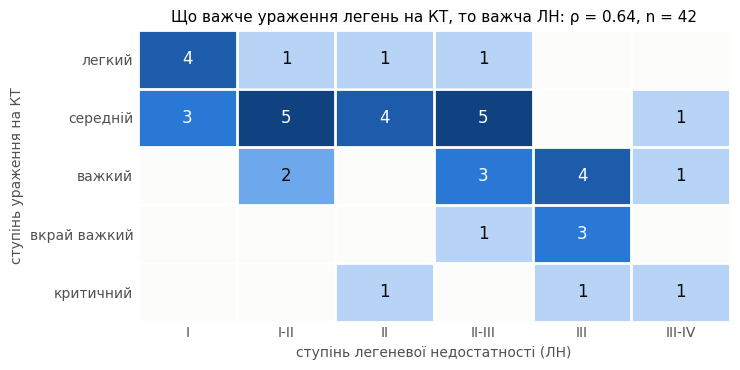

In [88]:
from matplotlib.colors import LinearSegmentedColormap
синя = LinearSegmentedColormap.from_list('синя', ['#fcfcfb', '#b7d3f6', '#6da7ec', '#2a78d6', '#1c5cab', '#104281'])

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.imshow(табл.values, cmap=синя, vmin=0, vmax=табл.values.max(), aspect='auto')
for i in range(табл.shape[0]):
    for j in range(табл.shape[1]):
        n = табл.values[i, j]
        if n > 0:
            ax.text(j, i, n, ha='center', va='center', fontsize=12,
                    color='white' if n >= 3 else '#0b0b0b')
ax.set_xticks(range(табл.shape[1]), табл.columns)
ax.set_yticks(range(табл.shape[0]), табл.index)
ax.set_xlabel('ступінь легеневої недостатності (ЛН)', color='#52514e')
ax.set_ylabel('ступінь ураження на КТ', color='#52514e')
ax.set_title(f'Що важче ураження легень на КТ, то важча ЛН: ρ = {rho:.2f}, n = {є.sum()}', fontsize=11)
ax.tick_params(length=0, labelcolor='#52514e')
ax.set_xticks(np.arange(-0.5, табл.shape[1]), minor=True)
ax.set_yticks(np.arange(-0.5, табл.shape[0]), minor=True)
ax.grid(which='minor', color='white', linewidth=2)
ax.tick_params(which='minor', length=0)
for край in ax.spines.values():
    край.set_visible(False)
plt.tight_layout()
plt.show()

In [89]:
алф_ст = df['ступінь КТ'].astype('category').cat.codes[є]
алф_лн = df['ЛН'].astype('category').cat.codes[є]
коди_ст = ст[є].cat.codes + 1
коди_лн = лн[є].cat.codes + 1
відс_ст = np.array([12.5, 37.5, 62.5, 80, 90])[ст[є].cat.codes]
пів_лн = np.array([1, 1.5, 2, 2.5, 3, 3.5])[лн[є].cat.codes]


def пірсон(x, y):
    return np.corrcoef(np.asarray(x, float), np.asarray(y, float))[0, 1]


print(f'Пірсон, алфавітні коди pandas:       r = {пірсон(алф_ст, алф_лн):+.3f}')
print(f'Пірсон, коди 1…5 і 1…6:              r = {пірсон(коди_ст, коди_лн):+.3f}')
print(f'Пірсон, % ураження і пів-ступені:    r = {пірсон(відс_ст, пів_лн):+.3f}')
print(f'Спірмен, ті самі два кодування:      ρ = {stats.spearmanr(коди_ст, коди_лн)[0]:+.3f} і '
      f'{stats.spearmanr(відс_ст, пів_лн)[0]:+.3f}')

Пірсон, алфавітні коди pandas:       r = -0.456
Пірсон, коди 1…5 і 1…6:              r = +0.600
Пірсон, % ураження і пів-ступені:    r = +0.624
Спірмен, ті самі два кодування:      ρ = +0.642 і +0.642


**Результат.** ρ Спірмена = 0.64 (p ≈ 5·10⁻⁶, n = 42): помірно сильний додатний монотонний зв’язок. Що важче ураження легень на КТ, то важча легенева недостатність: медіанний ступінь ЛН зростає від I при легкому ураженні до III при вкрай важкому й критичному. Зв’язок не повний, бо КТ показує, яка частина легень уражена, а ЛН — наскільки легені справляються з диханням, і це залежить ще від віку, супутніх хвороб і моменту обстеження.

**Чому Пірсона тут не можна інтерпретувати.** Пірсон міряє лінійний зв’язок між числами, тобто вважає відстані між кодами справжніми. На алфавітних кодах pandas «легкий» отримав 6, а «важкий» 0, і r = −0.46 має навіть протилежний знак. На двох правильно впорядкованих, але однаково довільних кодуваннях r = 0.60 і 0.62: число залежить від того, які числа ми приписали рівням, а не від пацієнтів. Спірмен в обох випадках дає ту саму 0.642, бо бачить лише порядок.

---
# Етап 5. Підготовка змінних до моделі

Шкала визначає не лише статистику, а й спосіб кодування.

| Шкала | Як готують до моделі |
|---|---|
| Номінальна | one-hot кодування; порядок категорій не вводять |
| Порядкова | впорядкована категорія або цілі коди із **заданим** порядком |
| Інтервальна | стандартизація; для дат — перехід до тривалостей |
| Відношень | нормалізація або стандартизація; можливе логарифмування |
| Ідентифікатор | у модель не беруть узагалі |

Для кожного свого стовпця вкажіть спосіб підготовки — і **виконайте його**
щонайменше для трьох стовпців різних шкал.

In [90]:
ПІДГОТОВКА = {
    'номер і/х': 'у модель не беремо: ідентифікатор нічого не каже про пацієнта, а номери ще й повторюються',
    'КТ опис': 'у модель не беремо: one-hot на 10 різних текстах дав би 10 стовпців з однією одиницею; '
               'за потреби витягти з тексту CO-RADS і ступінь КТ як порядкові ознаки',
    'ЛН': 'цілі коди за порядком, заданим вручну: I = 1, I-II = 2, …, III-IV = 6 (не алфавітні коди)',
    'Виписка': 'саму дату не беремо: переходимо до тривалості Виписка − Поступлення в днях (шкала відношень), '
               'відкидаємо тривалості, що суперечать «Ліжко днів», і стандартизуємо; для прогнозу смерті це витік, '
               'бо тривалість відома лише після результату',
    'КТ': 'текст розбираємо в частку (середина діапазону, для «до 17%» — сама межа); частка 0–1 уже нормована, '
          'а відсутність запису КТ (78 зі 121) — окремий прапорець',
    'Прокальцитонін': 'логарифм log10, бо розподіл дуже скошений (медіана 0.1, максимум 18.22), потім стандартизація',
    'БРзаг2': 'стандартизація (z-оцінка); один викид 60.5 при медіані 15.3 перевірити, за потреби логарифмувати',
    'Сечов1': 'min-max нормалізація з перевіркою варіативності; перед нею з’ясувати значення 60 і 68 (ймовірно, мг/дл)',
}
for c in МОЇ:
    ПІДГОТОВКА.setdefault(c, '')

pd.DataFrame([(c, ПАСПОРТ[c][0], ПІДГОТОВКА[c]) for c in МОЇ],
             columns=['Стовпець', 'Шкала', 'Як готуємо'])

,Стовпець,Шкала,Як готуємо
0,номер і/х,ідентифікатор,"у модель не беремо: ідентифікатор нічого не каже про пацієнта, а номери ще й повторюються"
1,КТ опис,номінальна,у модель не беремо: one-hot на 10 різних текстах дав би 10 стовпців з однією одиницею; за потреби витягти з тексту CO-RADS і ступінь КТ як порядкові ознаки
2,ЛН,порядкова,"цілі коди за порядком, заданим вручну: I = 1, I-II = 2, …, III-IV = 6 (не алфавітні коди)"
3,Виписка,інтервальна,"саму дату не беремо: переходимо до тривалості Виписка − Поступлення в днях (шкала відношень), відкидаємо тривалості, що суперечать «Ліжко днів», і стандартизуємо; для прогнозу смерті це витік, бо тривалість відома лише після результату"
4,КТ,абсолютна,"текст розбираємо в частку (середина діапазону, для «до 17%» — сама межа); частка 0–1 уже нормована, а відсутність запису КТ (78 зі 121) — окремий прапорець"
5,Прокальцитонін,відношень,"логарифм log10, бо розподіл дуже скошений (медіана 0.1, максимум 18.22), потім стандартизація"
6,БРзаг2,відношень,"стандартизація (z-оцінка); один викид 60.5 при медіані 15.3 перевірити, за потреби логарифмувати"
7,Сечов1,відношень,"min-max нормалізація з перевіркою варіативності; перед нею з’ясувати значення 60 і 68 (ймовірно, мг/дл)"


In [91]:
def мінмакс(x):
    """Нормалізація (x − min) / (max − min) з перевіркою, що стовпець не сталий."""
    x = pd.to_numeric(x, errors='coerce')
    розмах = x.max() - x.min()
    if not розмах > 0:                        # max = min (або все NaN): 0/0 дав би мовчазний NaN
        raise ValueError(f'{x.name}: max = min, нормалізувати не можна')
    return (x - x.min()) / розмах


поступ = pd.to_datetime(df['Поступлення'], errors='coerce')
тривалість = (випис - поступ).dt.days
ліжко_днів = pd.to_numeric(df['Ліжко днів'], errors='coerce')
# від’ємна тривалість або розбіжність із «Ліжко днів» більш ніж на день означає помилку в одній з дат
помилкові = (тривалість < 0) | ((тривалість - ліжко_днів).abs() > 1)
тривалість = тривалість.where(~помилкові)
пкт_log = np.log10(df['Прокальцитонін'])

підготовлено = pd.DataFrame({
    'ЛН_код':         значення('ЛН').cat.codes + 1,                          # порядкова
    'тривалість_дн':  тривалість,                                             # інтервальна → тривалість
    'тривалість_z':   (тривалість - тривалість.mean()) / тривалість.std(),
    'КТ_частка':      кт,                                                     # абсолютна
    'КТ_немає':       кт.isna().astype(int),
    'ПКТ_log10_z':    (пкт_log - пкт_log.mean()) / пкт_log.std(),            # відношень
    'Сечов1_мінмакс': мінмакс(df['Сечов1']),                                  # відношень
})
print(f'Тривалість: помилкових {помилкові.sum()} (від’ємних {(випис < поступ).sum()}), '
      f'лишилось {тривалість.notna().sum()}, медіана {тривалість.median():.0f} дн.')
підготовлено.describe().T.round(2)

Тривалість: помилкових 5 (від’ємних 2), лишилось 113, медіана 15 дн.


,count,mean,std,min,25%,50%,75%,max
ЛН_код,121.0,3.57,1.20,1.00,3.00,4.00,4.00,6.00
тривалість_дн,113.0,17.98,13.12,2.00,10.00,15.00,22.00,78.00
тривалість_z,113.0,0.00,1.00,-1.22,-0.61,-0.23,0.31,4.58
КТ_частка,43.0,0.42,0.22,0.05,0.26,0.35,0.64,0.80
КТ_немає,121.0,0.64,0.48,0.00,0.00,1.00,1.00,1.00
ПКТ_log10_z,46.0,-0.00,1.00,-1.09,-0.33,-0.33,-0.17,4.35
Сечов1_мінмакс,117.0,0.09,0.13,0.00,0.04,0.06,0.10,1.00


**Перед нормалізацією** обов'язково перевірте варіативність. Стовпець, у якому
всі значення однакові, дасть нуль у знаменнику — і мовчазний `NaN` замість помилки.

In [92]:
for c in МОЇ:
    з = pd.to_numeric(df[c], errors='coerce').dropna()
    if len(з) and з.nunique() == 1:
        print(f'УВАГА: {c} — сталий стовпець, нормалізація дасть ділення на нуль')
    elif len(з) and з.max() == з.min():
        print(f'УВАГА: {c} — max дорівнює min')
print('Перевірку варіативності виконано.')

Перевірку варіативності виконано.


In [93]:
ф2 = df['ФЕРИТ2']
наївна = (ф2 - ф2.min()) / (ф2.max() - ф2.min())
print('Наївна формула на ФЕРИТ2:', наївна.notna().sum(), 'чисел, решта NaN — і жодної помилки')
try:
    мінмакс(ф2)
except ValueError as e:
    print('мінмакс() зупиняється з поясненням:', e)

Наївна формула на ФЕРИТ2: 0 чисел, решта NaN — і жодної помилки
мінмакс() зупиняється з поясненням: ФЕРИТ2: max = min, нормалізувати не можна


In [94]:
assert all(len(ПІДГОТОВКА[c].strip()) >= 15 for c in МОЇ), \
    'Для кожного стовпця вкажіть спосіб підготовки'
assert len(БЕЗГЛУЗДІ) >= 3, 'Етап 3 не завершено'
print('Самоперевірка 2 пройдена.')

Самоперевірка 2 пройдена.


---
# Етап 6. Виправлення чужого аналізу

Відкрийте файл **`ЛР3_помилковий_аналіз.ipynb`**. Це звіт, який виконується
без жодної помилки й містить десять хибних місць.

Для кожного з десяти заповніть рядок нижче:

* **розділ** — номер розділу звіту;
* **що не так** — яка шкала порушена або яке припущення хибне;
* **чому число неправильне** — що саме воно означає насправді;
* **як правильно** — коректний варіант або обґрунтована відмова від показника.

In [95]:
ВИПРАВЛЕННЯ = [
    (1, 'Середнє номінальної змінної: «помер/жив» — номінальна шкала, 1 і 2 лише коди категорій',
     'Середнє кодів 1 і 2 — це 1 + частка тих, хто вижив, а не «результат посередині»: з кодами 0 і 1 вийшло б 0.50, '
     'з кодами 10 і 20 — 14.96, тож саме число залежить від довільних кодів',
     'Частоти й частки: померли 61 зі 121 (50.4%), вижили 60 (49.6%)'),
    (2, 'Номінальну змінну не почищено: одну стать записано двома способами («ж» і «жін», «ч» і «чол»)',
     '«4 статі» — артефакт введення: nunique рахує різні рядки, а не різні категорії, тому частка жінок 46% '
     'занижена — ще 19 жінок записано як «жін»',
     'Звести написання до двох категорій (перша літера після strip): жінок 75 (62%), чоловіків 46 (38%)'),
    (3, 'Порядкову шкалу впорядковано за алфавітом і усереднено, а написання не почищено',
     '«Найлегший — важкий, найважчий — середній» — це алфавіт, а не тяжкість; 12 рядків замість 5 рівнів через '
     'одруківки й пробіли; «середнє 5.9 → легкий» — середнє алфавітних номерів брудних написань',
     'Звести 12 написань до 5 рівнів, задати порядок вручну (pd.Categorical, ordered=True), узяти медіану й моду: '
     'обидві «середній»; найлегший — легкий, найважчий — критичний'),
    (4, 'Дані непридатні для середнього: КТ записано у двох несумісних кодуваннях — частки (0.3) і текст («70-80%»)',
     'pd.to_numeric(errors="coerce") мовчки зробив NaN із 16 текстових записів і рядка пробілів, тож 39.6% '
     'пораховано на 27 записах із 44; відкинуті записи в середньому важчі (47%), тому середнє занижене',
     'Розібрати текст у частку (середина діапазону, «до 17%» — сама межа) і вказати n: середнє 42.5%, медіана 35% '
     'на 43 пацієнтах — і лише серед тих, у кого КТ записано'),
    (5, 'Дані непридатні: одне значення сатурації записано часткою (0.9) серед відсотків',
     'Мінімум 0.9% фізично неможливий — це 90%, записані як 0.9; він зсуває середнє на 0.74 п.п., а «більшість» '
     'середнім не доводиться взагалі',
     'Виправити кодування (x ≤ 1 → x·100): середнє 82.79, медіана 84, мінімум 50; «більшість» показує частка: '
     'SpO2 < 90% у 90 зі 120 пацієнтів (75%)'),
    (6, 'Коефіцієнт варіації для інтервальної шкали: нуль дат умовний (1970-01-01)',
     'CV = std / mean ділить розкид на відстань від умовного нуля: від 1970 року 0.595%, від нуля Excel 0.254%, '
     'від 2021-01-01 вже 30%; про однорідність потоку госпіталізацій число нічого не каже',
     'Розкид дат міряти в днях (std 113 дн., з 2021-02-25 по 2022-06-03), а однорідність — числом '
     'госпіталізацій за місяць: від 0 до 30, тобто потік зовсім не рівномірний'),
    (7, 'Пірсон для двох номінальних змінних: стать і результат лікування — категорії, а не величини',
     'Знак r залежить лише від того, кого закодовано одиницею, «лінійного зв’язку» між категоріями не буває, '
     'а 0.177 при летальності жінок 57% проти 39% у чоловіків — не «близько до нуля»',
     'Таблиця спряженості, χ² і коефіцієнт Крамера: χ² = 3.78, p = 0.052, V = 0.18 — слабкий зв’язок на межі '
     'значущості, а не його відсутність'),
    (8, 'Нормалізація без перевірки варіативності й без огляду на шкали: min-max застосовано до всіх 40 числових стовпців',
     'ФЕРИТ2 заповнений лише в одного пацієнта, тому max − min = 0 і формула мовчки дала 0/0 = NaN; «усі значення '
     'в [0, 1]» неправда, а заодно «нормалізовано» номінальний код помер/жив',
     'Перед нормалізацією перевіряти max > min і пропускати сталі стовпці; номінальні коди не нормалізувати, а кодувати one-hot'),
    (9, 'Хибне припущення, що будь-який пропуск означає «невідомо»: dropna() видаляє рядок через будь-який пропуск',
     'Отримано не «повністю заповнений набір», а 0 рядків: дата розтину порожня в усіх 60 живих (розтину не було), '
     'а ФЕРИТ2 є лише в одного пацієнта, і той живий, тож пропуск є в кожному рядку',
     'Вирішувати по стовпцях: майже порожні відкинути, структурні пропуски закодувати, а dropna робити лише за '
     'потрібними стовпцями: за 35 заповненими на ≥ 90% лишається 91 рядок'),
    (10, 'Витік цільової змінної: дата розтину є лише в померлих, тобто це закодований результат, а не предиктор',
     'r = 1.00 означає не силу прогнозу, а те, що ознака повторює ціль: дата розтину заповнена в усіх 61 померлого '
     'й у жодного живого; до того ж ІЛ6-2 у рейтингу пораховано лише на 6 пацієнтах',
     'Вилучити ознаки, відомі лише після результату, для кожної ознаки рахувати точково-бісеріальний r з n і p, '
     'відкинути ознаки з малим n: першими стають Лім2 (r = −0.64), Л2 і вік'),
]

assert len(ВИПРАВЛЕННЯ) == 10, f'Знайдено {len(ВИПРАВЛЕННЯ)} помилок із 10'
for р in ВИПРАВЛЕННЯ:
    assert len(р) == 4 and all(str(x).strip() for x in р), 'Заповніть усі чотири поля'
    assert len(str(р[2])) >= 30 and len(str(р[3])) >= 25, 'Пояснення закороткі'

pd.DataFrame(ВИПРАВЛЕННЯ, columns=['Розділ', 'Що не так', 'Чому число неправильне', 'Як правильно'])

,Розділ,Що не так,Чому число неправильне,Як правильно
0,1,"Середнє номінальної змінної: «помер/жив» — номінальна шкала, 1 і 2 лише коди категорій","Середнє кодів 1 і 2 — це 1 + частка тих, хто вижив, а не «результат посередині»: з кодами 0 і 1 вийшло б 0.50, з кодами 10 і 20 — 14.96, тож саме число залежить від довільних кодів","Частоти й частки: померли 61 зі 121 (50.4%), вижили 60 (49.6%)"
1,2,"Номінальну змінну не почищено: одну стать записано двома способами («ж» і «жін», «ч» і «чол»)","«4 статі» — артефакт введення: nunique рахує різні рядки, а не різні категорії, тому частка жінок 46% занижена — ще 19 жінок записано як «жін»","Звести написання до двох категорій (перша літера після strip): жінок 75 (62%), чоловіків 46 (38%)"
2,3,"Порядкову шкалу впорядковано за алфавітом і усереднено, а написання не почищено","«Найлегший — важкий, найважчий — середній» — це алфавіт, а не тяжкість; 12 рядків замість 5 рівнів через одруківки й пробіли; «середнє 5.9 → легкий» — середнє алфавітних номерів брудних написань","Звести 12 написань до 5 рівнів, задати порядок вручну (pd.Categorical, ordered=True), узяти медіану й моду: обидві «середній»; найлегший — легкий, найважчий — критичний"
3,4,Дані непридатні для середнього: КТ записано у двох несумісних кодуваннях — частки (0.3) і текст («70-80%»),"pd.to_numeric(errors=""coerce"") мовчки зробив NaN із 16 текстових записів і рядка пробілів, тож 39.6% пораховано на 27 записах із 44; відкинуті записи в середньому важчі (47%), тому середнє занижене","Розібрати текст у частку (середина діапазону, «до 17%» — сама межа) і вказати n: середнє 42.5%, медіана 35% на 43 пацієнтах — і лише серед тих, у кого КТ записано"
4,5,Дані непридатні: одне значення сатурації записано часткою (0.9) серед відсотків,"Мінімум 0.9% фізично неможливий — це 90%, записані як 0.9; він зсуває середнє на 0.74 п.п., а «більшість» середнім не доводиться взагалі","Виправити кодування (x ≤ 1 → x·100): середнє 82.79, медіана 84, мінімум 50; «більшість» показує частка: SpO2 < 90% у 90 зі 120 пацієнтів (75%)"
5,6,Коефіцієнт варіації для інтервальної шкали: нуль дат умовний (1970-01-01),"CV = std / mean ділить розкид на відстань від умовного нуля: від 1970 року 0.595%, від нуля Excel 0.254%, від 2021-01-01 вже 30%; про однорідність потоку госпіталізацій число нічого не каже","Розкид дат міряти в днях (std 113 дн., з 2021-02-25 по 2022-06-03), а однорідність — числом госпіталізацій за місяць: від 0 до 30, тобто потік зовсім не рівномірний"
6,7,"Пірсон для двох номінальних змінних: стать і результат лікування — категорії, а не величини","Знак r залежить лише від того, кого закодовано одиницею, «лінійного зв’язку» між категоріями не буває, а 0.177 при летальності жінок 57% проти 39% у чоловіків — не «близько до нуля»","Таблиця спряженості, χ² і коефіцієнт Крамера: χ² = 3.78, p = 0.052, V = 0.18 — слабкий зв’язок на межі значущості, а не його відсутність"
7,8,Нормалізація без перевірки варіативності й без огляду на шкали: min-max застосовано до всіх 40 числових стовпців,"ФЕРИТ2 заповнений лише в одного пацієнта, тому max − min = 0 і формула мовчки дала 0/0 = NaN; «усі значення в [0, 1]» неправда, а заодно «нормалізовано» номінальний код помер/жив","Перед нормалізацією перевіряти max > min і пропускати сталі стовпці; номінальні коди не нормалізувати, а кодувати one-hot"
8,9,"Хибне припущення, що будь-який пропуск означає «невідомо»: dropna() видаляє рядок через будь-який пропуск","Отримано не «повністю заповнений набір», а 0 рядків: дата розтину порожня в усіх 60 живих (розтину не було), а ФЕРИТ2 є лише в одного пацієнта, і той живий, тож пропуск є в кожному рядку","Вирішувати по стовпцях: майже порожні відкинути, структурні пропуски закодувати, а dropna робити лише за потрібними стовпцями: за 35 заповненими на ≥ 90% лишається 91 рядок"
9,10,"Витік цільової змінної: дата розтину є лише в померлих, тобто це закодований результат, а не предиктор","r = 1.00 означає не силу прогнозу, а те, що ознака повторює ціль: дата розтину заповнена в ус

### Виправте щонайменше три помилки в коді

Оберіть три з десяти та покажіть правильне обчислення поруч із неправильним.

In [96]:
print('Розділ 1. «помер/жив» — номінальна шкала: замість середнього кодів рахуємо частки')
print(f"   було : середнє = {df['помер/жив'].mean():.2f}")
print(f"   стало: {df['помер/жив'].map({1: 'помер', 2: 'вижив'}).value_counts().to_dict()}, "
      f"летальність {(df['помер/жив'] == 1).mean():.1%}")

print('\nРозділ 2. Стать — дві категорії, записані чотирма способами')
стать = df['Стать'].str.strip().str[0]                        # «жін» → «ж», «чол» → «ч»
print(f"   було : {df['Стать'].nunique()} «статі» {df['Стать'].value_counts().to_dict()}")
print(f"   стало: {стать.nunique()} статі {стать.value_counts().to_dict()}")

print('\nРозділ 5. Сатурація — одне значення записано часткою замість відсотків')
spo2 = df['spO2 без дот']
spo2_ок = spo2.where(spo2 > 1, spo2 * 100)                    # 0.9 → 90
print(f'   було : середнє {spo2.mean():.2f}, мінімум {spo2.min()}')
print(f'   стало: середнє {spo2_ок.mean():.2f}, медіана {spo2_ок.median():.0f}, мінімум {spo2_ок.min():.0f}')
print(f'   «більшість» доводить частка, а не середнє: SpO2 < 90% у {(spo2_ок < 90).sum()} з {spo2_ок.notna().sum()}')

Розділ 1. «помер/жив» — номінальна шкала: замість середнього кодів рахуємо частки
   було : середнє = 1.50
   стало: {'помер': 61, 'вижив': 60}, летальність 50.4%

Розділ 2. Стать — дві категорії, записані чотирма способами
   було : 4 «статі» {'ж': 56, 'ч': 34, 'жін': 19, 'чол': 12}
   стало: 2 статі {'ж': 75, 'ч': 46}

Розділ 5. Сатурація — одне значення записано часткою замість відсотків
   було : середнє 82.05, мінімум 0.9
   стало: середнє 82.79, медіана 84, мінімум 50
   «більшість» доводить частка, а не середнє: SpO2 < 90% у 90 з 120


In [97]:
ст_усі = значення('ступінь КТ')
коди_ст_усі = ст_усі.dropna().cat.codes
print('було : найлегший — важкий, найважчий — середній, «середній ступінь» 5.9 → легкий')
print('стало:', ст_усі.value_counts(sort=False).to_dict())
print(f'   найлегший — {ст_усі.min()}, найважчий — {ст_усі.max()}')
print(f'   медіана — {ПОРЯДОК["ступінь КТ"][int(коди_ст_усі.quantile(0.5, interpolation="lower"))]}, '
      f'мода — {ст_усі.mode()[0]}')

було : найлегший — важкий, найважчий — середній, «середній ступінь» 5.9 → легкий
стало: {'легкий': 7, 'середній': 18, 'важкий': 10, 'вкрай важкий': 4, 'критичний': 3}
   найлегший — легкий, найважчий — критичний
   медіана — середній, мода — середній


In [98]:
print(f'було : середнє {100 * кт_наївно.mean():.1f}% на {кт_наївно.notna().sum()} записах')
print(f'стало: середнє {100 * кт.mean():.1f}%, медіана {100 * кт.median():.0f}% на {кт.notna().sum()} записах')
print(f'   текстові записи в середньому {100 * кт[текст_кт].mean():.1f}%, числові {100 * кт[~текст_кт].mean():.1f}%: '
      f'наївне середнє відкинуло саме важчі випадки')

було : середнє 39.6% на 27 записах
стало: середнє 42.5%, медіана 35% на 43 записах
   текстові записи в середньому 47.5%, числові 39.6%: наївне середнє відкинуло саме важчі випадки


In [99]:
дати = pd.to_datetime(df['Поступлення'], errors='coerce').dropna()
for нуль in ['1970-01-01', '1899-12-30', '2021-01-01']:
    дні = (дати - pd.Timestamp(нуль)).dt.days
    print(f'CV, дні від {нуль}: {100 * дні.std() / дні.mean():7.3f}%   (std та сама: {дні.std():.0f} дн.)')
по_місяцях = (дати.dt.to_period('M').value_counts()
              .reindex(pd.period_range(дати.min(), дати.max(), freq='M'), fill_value=0))   # місяці без госпіталізацій теж
print(f'\nправильно: розкид у днях — std {дні.std():.0f} дн., з {дати.min().date()} по {дати.max().date()};')
print(f'госпіталізацій за місяць від {по_місяцях.min()} до {по_місяцях.max()} — потік зовсім не однорідний')

CV, дні від 1970-01-01:   0.595%   (std та сама: 113 дн.)
CV, дні від 1899-12-30:   0.254%   (std та сама: 113 дн.)
CV, дні від 2021-01-01:  30.041%   (std та сама: 113 дн.)

правильно: розкид у днях — std 113 дн., з 2021-02-25 по 2022-06-03;
госпіталізацій за місяць від 0 до 30 — потік зовсім не однорідний


In [100]:
# Розділ 7. Стать × результат — дві номінальні змінні: таблиця спряженості, χ² і V Крамера
табл7 = pd.crosstab(стать, df['помер/жив'].map({1: 'помер', 2: 'вижив'}))
chi2, p7, _, _ = stats.chi2_contingency(табл7, correction=False)
V = np.sqrt(chi2 / (табл7.values.sum() * (min(табл7.shape) - 1)))
летальність = табл7['помер'] / табл7.sum(axis=1)
print(табл7.to_string())
print(f"\nлетальність: жінки {летальність['ж']:.0%}, чоловіки {летальність['ч']:.0%}")
r_стать = стать.map({'ч': 0, 'ж': 1}).corr((df['помер/жив'] == 1).astype(int))
print(f'χ² = {chi2:.2f}, p = {p7:.3f}, V Крамера = {V:.2f}')
print(f'|r| колеги на кодах 0/1 = {abs(r_стать):.2f}: для таблиці 2×2 це те саме, що V')
print('зв’язок слабкий і на межі значущості, а не відсутній:')
print('помилка колеги не в самому числі, а в його прочитанні')

помер/жив  вижив  помер
Стать                  
ж             32     43
ч             28     18

летальність: жінки 57%, чоловіки 39%
χ² = 3.78, p = 0.052, V Крамера = 0.18
|r| колеги на кодах 0/1 = 0.18: для таблиці 2×2 це те саме, що V
зв’язок слабкий і на межі значущості, а не відсутній:
помилка колеги не в самому числі, а в його прочитанні


In [101]:
# Розділ 8. Нормалізуємо лише стовпці з варіацією і без номінальних кодів
нормалізовані = {}
for c in df.select_dtypes('number').columns.drop('помер/жив'):     # номінальний код не нормалізуємо
    try:
        нормалізовані[c] = мінмакс(df[c])
    except ValueError as e:
        print('пропущено —', e)
в_межах = all(s.dropna().between(0, 1).all() for s in нормалізовані.values())
print(f'нормалізовано {len(нормалізовані)} стовпців, усі значення в [0, 1]: {в_межах}')

# Розділ 9. dropna() вимагає повного рядка, а порожня клітинка не завжди означає «невідомо»
print(f'\ndropna() на всьому файлі: {len(df.dropna())} рядків')
живі = df['помер/жив'] == 2
print(f"дата розтину порожня в живих: {df.loc[живі, 'Дата розтину'].isna().sum()} з {живі.sum()}; "
      f"ФЕРИТ2 заповнений у {df['ФЕРИТ2'].notna().sum()} пацієнта")
заповненість = df.notna().mean()
основні = заповненість[заповненість >= 0.9].index               # стовпці, заповнені щонайменше на 90%
print(f'dropna лише за {len(основні)} стовпцями, заповненими на ≥ 90%: лишається рядків {len(df[основні].dropna())}')

пропущено — ФЕРИТ2: max = min, нормалізувати не можна
нормалізовано 38 стовпців, усі значення в [0, 1]: True

dropna() на всьому файлі: 0 рядків
дата розтину порожня в живих: 60 з 60; ФЕРИТ2 заповнений у 1 пацієнта
dropna лише за 35 стовпцями, заповненими на ≥ 90%: лишається рядків 91


In [102]:
# Розділ 10. Дата розтину є лише в померлих — це витік цільової змінної
print(pd.crosstab(df['помер/жив'].map({1: 'помер', 2: 'вижив'}),
                  df['Дата розтину'].notna().map({True: 'є дата розтину', False: 'немає'})).to_string())
print()
ціль = (df['помер/жив'] == 1).astype(int)
рядки = []
for c in df.select_dtypes('number').columns.drop('помер/жив'):   # дату розтину навмисно не додаємо
    є_дані = df[c].notna()
    if є_дані.sum() >= 30 and df.loc[є_дані, c].nunique() > 1:    # на 6 пацієнтах коефіцієнт нічого не значить
        r_c, p_c = stats.pointbiserialr(ціль[є_дані], df.loc[є_дані, c])
        рядки.append((c, int(є_дані.sum()), round(r_c, 3), round(p_c, 4)))
рейтинг = pd.DataFrame(рядки, columns=['ознака', 'n', 'r', 'p'])
рейтинг.loc[рейтинг['r'].abs().sort_values(ascending=False).index].head(8).reset_index(drop=True)

Дата розтину  немає  є дата розтину
помер/жив                          
вижив            60               0
помер             0              61



,ознака,n,r,p
0,Лім2,104,-0.645,0.0000
1,Л2,104,0.480,0.0000
2,Вік,121,0.449,0.0000
3,П/Я2,104,0.395,0.0000
4,АЛАТ1,115,0.392,0.0000
5,АСАТ1,114,0.388,0.0000
6,АСАТ2,104,0.387,0.0000
7,ШОЕ2,104,0.369,0.0001


---
# Етап 7. Висновки та індивідуальне питання

In [103]:
ВИСНОВКИ = [
    'Стовпець КТ записано у двох несумісних кодуваннях: 27 значень — частки (0.3), 16 — текст «70-80%» чи «до 17%», '
    'ще один — самі пробіли. Наївне середнє 39.6% рахує лише частки; після розбору тексту середнє 42.5% на 43 '
    'пацієнтах, бо текстом записані важчі випадки (47% проти 40%).',
    'Ступінь ураження легень на КТ і ступінь легеневої недостатності пов’язані помірно сильним монотонним зв’язком: '
    'ρ Спірмена = 0.64, p < 0.001, n = 42; медіанна ЛН зростає від I при легкому ураженні до III при вкрай важкому '
    'й критичному. Пірсон на алфавітних кодах pandas дав −0.46, тобто протилежний знак.',
    'Прокальцитонін, білірубін і сечовина належать до шкали відношень, але середнє описує їх погано: у '
    'прокальцитоніну 30 із 46 значень рівно 0.1, а середнє 0.75 нг/мл у 7.5 раза більше за медіану через два '
    'значення 10 і 18.22; у сечовини 60 і 68 при нормальному креатиніні, ймовірно, записані в мг/дл.',
    'Виписка — інтервальна шкала: коефіцієнт варіації дат залежить від точки відліку, а осмислена величина — '
    'тривалість Виписка − Поступлення. Дві дати («24.024.2021», «20.24.2021») не розпізнаються, а ще п’ять дають '
    'тривалість, яка суперечить стовпцю «Ліжко днів», зокрема дві від’ємні (−14 і −29 днів).',
    'Номер історії хвороби — ідентифікатор, і навіть як ключ він ненадійний: 119 унікальних значень на 121 рядок, '
    'номери 1837 і 2526 належать різним пацієнтам, а «середній номер» 1770 pandas рахує без жодної скарги.',
]
assert len(ВИСНОВКИ) >= 3 and all(len(в) >= 60 for в in ВИСНОВКИ), \
    'Потрібні три змістовні висновки'
for i, в in enumerate(ВИСНОВКИ, 1):
    print(f'{i}. {в}')

1. Стовпець КТ записано у двох несумісних кодуваннях: 27 значень — частки (0.3), 16 — текст «70-80%» чи «до 17%», ще один — самі пробіли. Наївне середнє 39.6% рахує лише частки; після розбору тексту середнє 42.5% на 43 пацієнтах, бо текстом записані важчі випадки (47% проти 40%).
2. Ступінь ураження легень на КТ і ступінь легеневої недостатності пов’язані помірно сильним монотонним зв’язком: ρ Спірмена = 0.64, p < 0.001, n = 42; медіанна ЛН зростає від I при легкому ураженні до III при вкрай важкому й критичному. Пірсон на алфавітних кодах pandas дав −0.46, тобто протилежний знак.
3. Прокальцитонін, білірубін і сечовина належать до шкали відношень, але середнє описує їх погано: у прокальцитоніну 30 із 46 значень рівно 0.1, а середнє 0.75 нг/мл у 7.5 раза більше за медіану через два значення 10 і 18.22; у сечовини 60 і 68 при нормальному креатиніні, ймовірно, записані в мг/дл.
4. Виписка — інтервальна шкала: коефіцієнт варіації дат залежить від точки відліку, а осмислена величина — трив

In [104]:
print('ВАШЕ ПИТАННЯ:'); print(В['питання']); print()

# Перевірка на моїх даних: та сама операція — ділення — на інтервальній шкалі і на шкалі відношень
cv_дат = {}
for нуль in ['1970-01-01', '1899-12-30', '2021-01-01']:
    дні = (випис - pd.Timestamp(нуль)).dt.days
    cv_дат[нуль] = 100 * дні.std() / дні.mean()
    print(f'CV дат виписки, дні від {нуль}: {cv_дат[нуль]:7.3f}%')
сечов = df['Сечов1'].dropna()
cv_ммоль = 100 * сечов.std() / сечов.mean()
cv_мгдл = 100 * (сечов * 6.006).std() / (сечов * 6.006).mean()     # 1 ммоль/л сечовини = 6.006 мг/дл
print(f'CV сечовини: {cv_ммоль:.3f}% у ммоль/л і {cv_мгдл:.3f}% у мг/дл')
print()

ВІДПОВІДЬ = (
    'В обох шкалах однакові проміжки між значеннями мають однаковий зміст, тому різниці допустимі. Відмінність у нулі: '
    'в інтервальній шкалі він умовний, у шкалі відношень — природний, тобто означає «величини немає».\n'
    'Інтервальна шкала у файлі — «Виписка». Нуль дат умовний: pandas рахує дні від 1970-01-01, Excel — від 1899-12-30, '
    'і жодна з цих дат не означає «часу немає». Різниця дат осмислена: Виписка − Поступлення дає тривалість лікування, '
    f'медіана {тривалість.median():.0f} дн. А от «дата А удвічі більша за дату Б» сенсу не має.\n'
    'Шкала відношень — «Сечов1»: 0 ммоль/л означає, що сечовини немає, тому 6.0 справді вдвічі більше за 3.0.\n'
    'Операція, допустима для шкали відношень і недопустима для інтервальної, — ділення значень, а разом із ним '
    'відношення «у k разів», коефіцієнт варіації, геометричне середнє й логарифм. Перевірка вище: CV дат виписки '
    f'{cv_дат["1970-01-01"]:.2f}% від 1970 року, {cv_дат["1899-12-30"]:.2f}% від нуля Excel і '
    f'{cv_дат["2021-01-01"]:.1f}% від 2021-01-01 — число залежить лише від вибору нуля. CV сечовини {cv_ммоль:.1f}% '
    'однаковий у ммоль/л і мг/дл, бо зміна одиниці множить усі значення на одну сталу, а нуль лишається нулем.'
)
assert len(ВІДПОВІДЬ.strip()) >= 200, 'Відповідь має бути розгорнутою (від 200 символів)'
print(ВІДПОВІДЬ)

ВАШЕ ПИТАННЯ:
У чому різниця між шкалою інтервалів і шкалою відношень? Знайдіть у файлі по одному прикладу кожної та поясніть, яка операція допустима для другої, але не для першої.

CV дат виписки, дні від 1970-01-01:   0.576%
CV дат виписки, дні від 1899-12-30:   0.246%
CV дат виписки, дні від 2021-01-01:  27.815%
CV сечовини: 91.519% у ммоль/л і 91.519% у мг/дл

В обох шкалах однакові проміжки між значеннями мають однаковий зміст, тому різниці допустимі. Відмінність у нулі: в інтервальній шкалі він умовний, у шкалі відношень — природний, тобто означає «величини немає».
Інтервальна шкала у файлі — «Виписка». Нуль дат умовний: pandas рахує дні від 1970-01-01, Excel — від 1899-12-30, і жодна з цих дат не означає «часу немає». Різниця дат осмислена: Виписка − Поступлення дає тривалість лікування, медіана 15 дн. А от «дата А удвічі більша за дату Б» сенсу не має.
Шкала відношень — «Сечов1»: 0 ммоль/л означає, що сечовини немає, тому 6.0 справді вдвічі більше за 3.0.
Операція, допустима дл

---
# Етап 8. Декларація про використання інструментів ШІ

Користуватися мовними моделями дозволено. Це нормальна інженерна практика.

**Обов'язковою є прозорість:** ви вказуєте, де саме і як скористалися інструментом —
так само, як у науковій статті вказують використане програмне забезпечення.
Задекларована допомога порушенням не є.

Порушенням є інше: здати роботу, яку ви не можете пояснити. На захисті вас
попросять показати конкретний рядок свого коду, пояснити, чому він саме такий,
і внести в нього невелику зміну на місці.

Для кожного етапу оберіть одне з формулювань:

* `'ні'` — інструментами ШІ не користувався
* `'синтаксис'` — питав про назву функції або синтаксис, код писав сам
* `'код, перевірено'` — код згенеровано, я його прочитав, перевірив і розумію
* `'текст, перероблено'` — згенеровано чернетку тексту, яку я переписав по суті
* `'текст, як є'` — згенерований текст залишено майже без змін

In [105]:
ДЕКЛАРАЦІЯ = {
    'етап 1 — паспорт змінних': 'синтаксис',
    'етап 2 — допустимі статистики': 'код, перевірено',
    'етап 3 — безлузді числа': 'код, перевірено',
    'етап 4 — міра зв\'язку': 'код, перевірено',
    'етап 5 — підготовка до моделі': 'код, перевірено',
    'етап 6 — виправлення аналізу': 'код, перевірено',
    'етап 7 — висновки й відповіді': 'текст, як є'
}

ЩО_САМЕ_Я_ПЕРЕВІРИВ = ('Запустив Restart & Run All, усі самоперевірки пройшли. Відкрив Ковід_дані_навчальні.xlsx '
                       'і знайшов там дати «24.04.2021» і «20.24.2021», текстові діапазони КТ на кшталт «70-80%» '
                       'та номери 1837 і 2576 у різних пацієнтів. Переконався, що Спірмен не змінюється при знаому '
                       'зростаючому кодуванні, а Пірсон змінюється, і що СУ дат залежить від точки відліку.')

ПІДТВЕРДЖУЮ = True


In [106]:
ФОРМУЛЮВАННЯ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}

перевірки = {
    'заповнено титульні поля':        bool(ПРІЗВИЩЕ_ІМЯ and ГРУПА and НОМЕР),
    'етап 1: паспорт із 8 стовпців':  all(ПАСПОРТ[c][0] and ПАСПОРТ[c][1] for c in МОЇ),
    'етап 3: три безглузді числа':    len(БЕЗГЛУЗДІ) >= 3,
    'етап 4: міру обрано й пояснено': bool(ОБРАНА_МІРА and len(ЧОМУ_САМЕ_ВОНА) >= 40),
    'етап 5: підготовку описано':     all(len(ПІДГОТОВКА[c].strip()) >= 15 for c in МОЇ),
    'етап 6: знайдено 10 помилок':    len(ВИПРАВЛЕННЯ) == 10,
    'етап 7: три висновки':           len(ВИСНОВКИ) >= 3,
    'етап 7: відповідь на питання':   len(ВІДПОВІДЬ.strip()) >= 200,
    'декларацію заповнено':           all(v in ФОРМУЛЮВАННЯ for v in ДЕКЛАРАЦІЯ.values()),
    'опис перевірки ≥ 120 символів':  len(ЩО_САМЕ_Я_ПЕРЕВІРИВ.strip()) >= 120,
    'підтвердження авторства':        ПІДТВЕРДЖУЮ is True,
}

print('ЧЕК-ЛИСТ ГОТОВНОСТІ')
print('=' * 52)
for назва, ок in перевірки.items():
    print(('  ГОТОВО     ' if ок else '  НЕ ГОТОВО ') + назва)
print('=' * 52)

assert all(перевірки.values()), 'Робота не готова до здачі — див. чек-лист вище'
print()
print(f'Робота варіанта {В["варіант"]} готова до захисту.')
print(f'{ПРІЗВИЩЕ_ІМЯ}, {ГРУПА}')

ЧЕК-ЛИСТ ГОТОВНОСТІ
  ГОТОВО     заповнено титульні поля
  ГОТОВО     етап 1: паспорт із 8 стовпців
  ГОТОВО     етап 3: три безглузді числа
  ГОТОВО     етап 4: міру обрано й пояснено
  ГОТОВО     етап 5: підготовку описано
  ГОТОВО     етап 6: знайдено 10 помилок
  ГОТОВО     етап 7: три висновки
  ГОТОВО     етап 7: відповідь на питання
  ГОТОВО     декларацію заповнено
  ГОТОВО     опис перевірки ≥ 120 символів
  ГОТОВО     підтвердження авторства

Робота варіанта 14 готова до захисту.
Мартин Максим, ШІ-31


---
### Перед здачею

Виконайте **Kernel → Restart & Run All**. Ноутбук має пройти згори донизу
без жодної помилки — це перше, що перевіряється на захисті.